In [9]:
import pandas as pd, numpy as np, joblib, json, os
import matplotlib.pyplot as plt
import shap
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_predict
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (classification_report, ConfusionMatrixDisplay,
                             roc_auc_score, average_precision_score, precision_recall_curve)
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from xgboost import XGBClassifier

df = pd.read_csv("../data/fraud_oracle.csv").drop(columns=["PolicyNumber"])  # ID sütunu, məlumat daşımır
X = df.drop(columns=["FraudFound_P"])
y = df["FraudFound_P"]

num_cols = X.select_dtypes(include="number").columns.tolist()
cat_cols = X.select_dtypes(exclude="number").columns.tolist()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)   # stratify: fraud faizi hər iki hissədə eyni qalır
print(len(X_train), len(X_test), y_train.mean().round(4), y_test.mean().round(4))

12336 3084 0.0598 0.06


In [10]:
from sklearn.preprocessing import StandardScaler

def make_prep(scale=False):
    return ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),
        ("num", StandardScaler() if scale else "passthrough", num_cols),
    ])

spw = (y_train == 0).sum() / (y_train == 1).sum()   # normal/fraud nisbəti

models = {
    "Logistic (baseline)": ImbPipeline([("prep", make_prep(scale=True)),
        ("m", LogisticRegression(max_iter=3000))]),
    "Logistic + class_weight": ImbPipeline([("prep", make_prep(scale=True)),
        ("m", LogisticRegression(max_iter=3000, class_weight="balanced"))]),
    "RandomForest + class_weight": ImbPipeline([("prep", make_prep()),
        ("m", RandomForestClassifier(n_estimators=300, min_samples_leaf=3,
              class_weight="balanced_subsample", n_jobs=-1, random_state=42))]),
    "RandomForest + SMOTE": ImbPipeline([("prep", make_prep()), ("smote", SMOTE(random_state=42)),
        ("m", RandomForestClassifier(n_estimators=300, min_samples_leaf=3,
              n_jobs=-1, random_state=42))]),
    "XGBoost + scale_pos_weight": ImbPipeline([("prep", make_prep()),
        ("m", XGBClassifier(n_estimators=400, max_depth=4, learning_rate=0.05,
              subsample=0.8, colsample_bytree=0.8, scale_pos_weight=spw,
              eval_metric="aucpr", random_state=42))]),
}

rows = []
for name, pipe in models.items():
    pipe.fit(X_train, y_train)
    proba = pipe.predict_proba(X_test)[:, 1]
    rows.append({"Model": name,
                 "ROC-AUC": roc_auc_score(y_test, proba),
                 "PR-AUC": average_precision_score(y_test, proba)})

results = pd.DataFrame(rows).sort_values("PR-AUC", ascending=False).round(3)
print("Təsadüfi model PR-AUC:", round(y_test.mean(), 3))
results

Təsadüfi model PR-AUC: 0.06


,Model,ROC-AUC,PR-AUC
4,XGBoost + scale_pos_weight,0.846,0.257
2,RandomForest + class_weight,0.837,0.244
3,RandomForest + SMOTE,0.828,0.219
0,Logistic (baseline),0.813,0.179
1,Logistic + class_weight,0.806,0.156


In [4]:
final = models["XGBoost + scale_pos_weight"]

cv = StratifiedKFold(5, shuffle=True, random_state=42)
oof = cross_val_predict(final, X_train, y_train, cv=cv, method="predict_proba")[:, 1]

p, r, t = precision_recall_curve(y_train, oof)
f1s = 2 * p * r / (p + r + 1e-9)
threshold = float(t[np.argmax(f1s[:-1])])
print("Seçilmiş threshold:", round(threshold, 3))

Seçilmiş threshold: 0.604


              precision    recall  f1-score   support

      Normal       0.97      0.85      0.91      2899
       Fraud       0.20      0.59      0.30       185

    accuracy                           0.84      3084
   macro avg       0.59      0.72      0.60      3084
weighted avg       0.92      0.84      0.87      3084

ROC-AUC: 0.846 | PR-AUC: 0.257


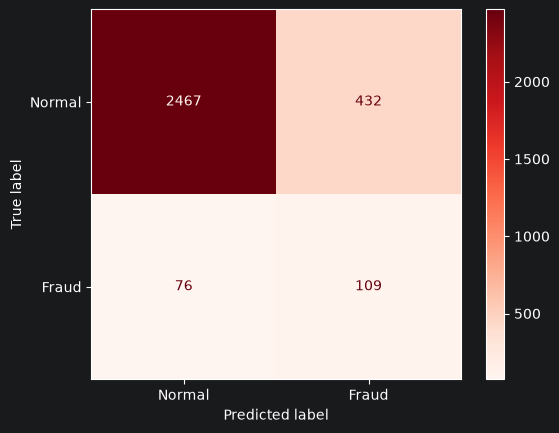

In [5]:
final.fit(X_train, y_train)
proba = final.predict_proba(X_test)[:, 1]
pred = (proba >= threshold).astype(int)

print(classification_report(y_test, pred, target_names=["Normal", "Fraud"]))
print("ROC-AUC:", round(roc_auc_score(y_test, proba), 3),
      "| PR-AUC:", round(average_precision_score(y_test, proba), 3))
ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=["Normal", "Fraud"], cmap="Reds")
plt.show()

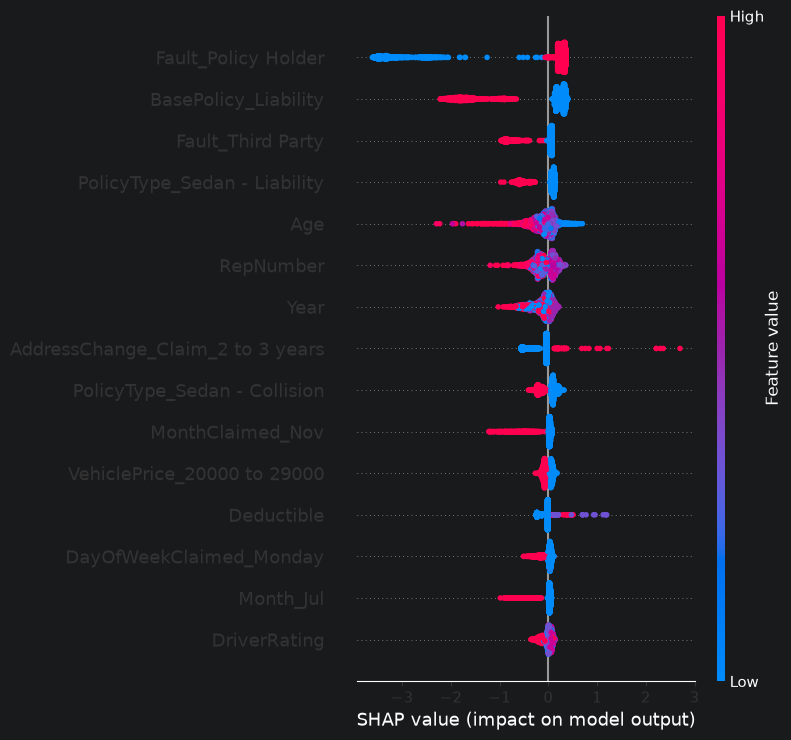

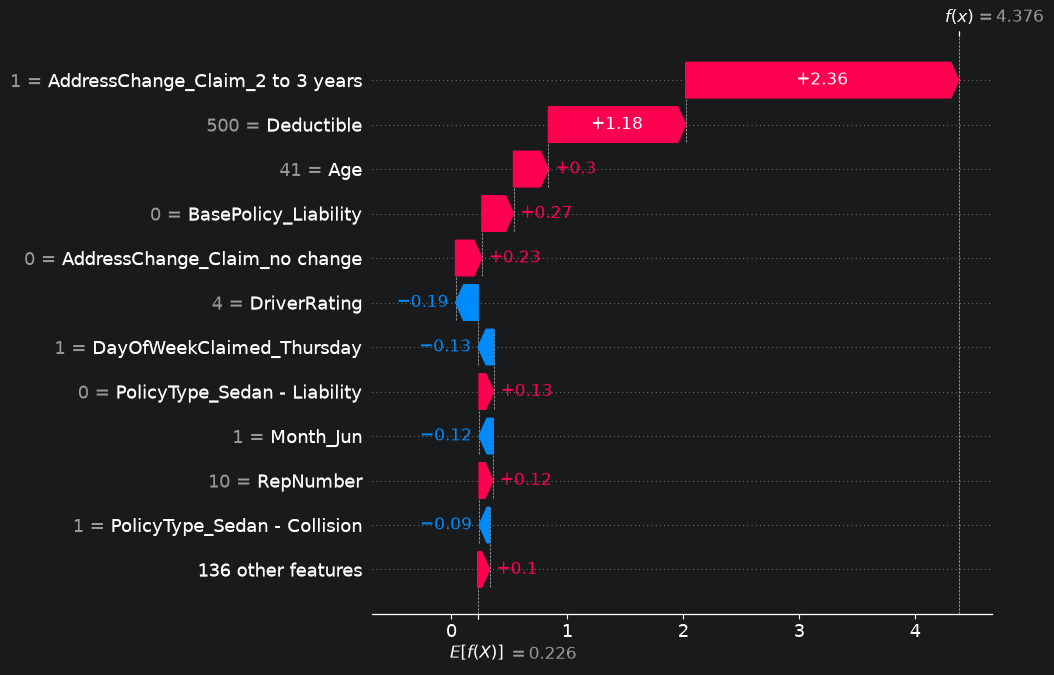

In [6]:
prep = final.named_steps["prep"]
model = final.named_steps["m"]
names = [n.split("__", 1)[1] for n in prep.get_feature_names_out()]
X_test_t = pd.DataFrame(prep.transform(X_test), columns=names)

explainer = shap.TreeExplainer(model)
sv = explainer(X_test_t)

shap.summary_plot(sv, X_test_t, max_display=15)       # ümumi: ən vacib amillər
shap.plots.waterfall(sv[int(np.argmax(proba))], max_display=12)   # ən şübhəli 1 iddia

In [7]:
os.makedirs("../models", exist_ok=True)
joblib.dump(final, "../models/fraud_model.joblib")
results.to_csv("../models/model_comparison.csv", index=False)

meta = {
    "threshold": threshold,
    "cat_cols": cat_cols,
    "num_cols": num_cols,
    "options": {c: sorted(X[c].unique().tolist()) for c in cat_cols},
    "cat_defaults": {c: X[c].mode()[0] for c in cat_cols},
    "num_stats": {c: {"min": int(X[c].min()), "max": int(X[c].max()),
                      "default": int(X[c].median())} for c in num_cols},
}
json.dump(meta, open("../models/meta.json", "w", encoding="utf-8"), ensure_ascii=False, indent=2)
print("Saxlandı")

Saxlandı
